<a href="https://colab.research.google.com/github/AMAO-06/AI-ML/blob/main/KNN_Health_Risk_Notebook_Metrics_Visualisation_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# K-Nearest Neighbours (KNN) Classification Practical
## Synthetic Health-Risk Dataset

**Goal:** Explore a dataset, prepare features, train a KNN classifier, choose `k` using cross-validation, evaluate performance, and visualize results.

**Important:** This is a synthetic educational dataset. The labels are generated by a simple rule with random noise; they are **not medical assessments** and must not be used for diagnosis or healthcare decisions.



## 1. Import libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, f1_score
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Create or load the dataset
This cell recreates the synthetic dataset with 1,000 rows. To use your existing CSV instead, set `LOAD_EXISTING_CSV = True` and upload the CSV when prompted.

In [ ]:
LOAD_EXISTING_CSV = False  # Change to True to upload your existing CSV

if LOAD_EXISTING_CSV:
    from google.colab import files
    uploaded = files.upload()
    csv_name = next(iter(uploaded))
    df = pd.read_csv(csv_name)
else:
    n_samples = 1000
    np.random.seed(42)

    age = np.random.randint(18, 80, n_samples)
    bmi = np.random.normal(27, 5, n_samples).clip(15, 45)
    systolic_bp = np.random.normal(125, 18, n_samples).clip(85, 200)
    diastolic_bp = np.random.normal(80, 12, n_samples).clip(50, 130)
    cholesterol = np.random.normal(200, 35, n_samples).clip(100, 350)
    daily_steps = np.random.normal(6500, 2500, n_samples).clip(500, 18000).astype(int)
    zip_code = np.random.randint(10000, 99999, n_samples)
    noise_score = np.random.normal(0, 1, n_samples)

    # Synthetic target rule: labels are generated from age, BMI, systolic BP and noise.
    risk_score = (
        0.35 * ((age - age.mean()) / age.std()) +
        0.35 * ((bmi - bmi.mean()) / bmi.std()) +
        0.30 * ((systolic_bp - systolic_bp.mean()) / systolic_bp.std()) +
        0.25 * noise_score
    )
    cutoffs = np.quantile(risk_score, [1/3, 2/3])
    risk_label = np.digitize(risk_score, cutoffs)

    df = pd.DataFrame({
        "Patient_ID": np.arange(1, n_samples + 1),
        "Age": age,
        "BMI": bmi,
        "Systolic_BP": systolic_bp,
        "Diastolic_BP": diastolic_bp,
        "Cholesterol": cholesterol,
        "Daily_Steps": daily_steps,
        "Zip_Code": zip_code,
        "Noise_Score": noise_score,
        "Risk_Label": risk_label
    })

df.head()

,Patient_ID,Age,BMI,Systolic_BP,Diastolic_BP,Cholesterol,Daily_Steps,Zip_Code,Noise_Score,Risk_Label
0,1,56,33.861889,123.422511,88.415890,177.586081,5998,22818,0.498605,2
1,2,69,23.611070,127.748922,80.803782,171.394659,7837,98222,0.753736,2
2,3,46,32.767659,135.587599,88.668655,173.217217,9097,73001,0.938724,2
3,4,32,25.124947,134.156028,69.265608,200.219958,7826,33977,-1.223139,0
4,5,60,23.529270,85.000000,97.093544,114.803826,8589,59832,0.306951,0


## 3. Understand the data

In [ ]:
print("Dataset shape:", df.shape)
display(df.head())
display(df.describe(include="all").T)
print("\\nMissing values per column:")
display(df.isnull().sum())

Dataset shape: (1000, 10)


,Patient_ID,Age,BMI,Systolic_BP,Diastolic_BP,Cholesterol,Daily_Steps,Zip_Code,Noise_Score,Risk_Label
0,1,56,33.861889,123.422511,88.415890,177.586081,5998,22818,0.498605,2
1,2,69,23.611070,127.748922,80.803782,171.394659,7837,98222,0.753736,2
2,3,46,32.767659,135.587599,88.668655,173.217217,9097,73001,0.938724,2
3,4,32,25.124947,134.156028,69.265608,200.219958,7826,33977,-1.223139,0
4,5,60,23.529270,85.000000,97.093544,114.803826,8589,59832,0.306951,0


,count,mean,std,min,25%,50%,75%,max
Patient_ID,1000.0,500.500000,288.819436,1.000000,250.750000,500.500000,750.250000,1000.000000
Age,1000.0,49.857000,18.114267,18.000000,35.000000,50.000000,66.000000,79.000000
BMI,1000.0,27.248088,5.278827,15.000000,23.861018,27.332155,30.815993,42.872211
Systolic_BP,1000.0,125.938296,18.063350,85.000000,113.444047,126.222873,138.293911,183.583651
Diastolic_BP,1000.0,80.132450,11.997097,50.000000,72.114966,80.357507,88.207580,119.125893
Cholesterol,1000.0,200.723880,34.472175,107.281516,178.017516,199.882071,224.213724,328.019563
Daily_Steps,1000.0,6467.755000,2440.968800,500.000000,4775.500000,6560.500000,8132.250000,13602.000000
Zip_Code,1000.0,55141.621000,26759.142076,10002.000000,30663.250000,56335.500000,78759.250000,99941.000000
Noise_Score,1000.0,-0.058052,1.019515,-3.347551,-0.753929,-0.053383,0.657635,2.979055
Risk_Label,1000.0,1.001000,0.817109,0.000000,0.000000,1.000000,2.000000,2.000000


\nMissing values per column:


,0
Patient_ID,0
Age,0
BMI,0
Systolic_BP,0
Diastolic_BP,0
Cholesterol,0
Daily_Steps,0
Zip_Code,0
Noise_Score,0
Risk_Label,0


## 4. Data cleaning and quality checks

### Why clean data first?
A model learns patterns from the data it receives. Missing values, duplicate records, incorrect data types, and impossible values can distort those patterns. Cleaning makes the dataset more consistent and reliable.

### Mean vs median vs mode
- **Mean** = sum of values divided by the number of values. It uses every value, so unusually high or low values can pull it up or down. It is useful for roughly symmetric numeric data without extreme outliers.
- **Median** = the middle value after sorting the values. With an even number of values, it is the average of the two middle values. It is resistant to extreme values and is often a sensible choice for skewed numeric data.
- **Mode** = the most frequently occurring value. It can be useful for categorical values, such as the most common category, and sometimes for numeric data.

**Why does this practical fill missing numeric features with the median?** Health-related numeric measurements can be skewed and may contain extreme values. The median is less affected by those extremes than the mean. This is a practical default, not a universal rule: the choice should depend on the data and the reason values are missing.

### Why these cleaning steps?
- **Check data types:** a number accidentally stored as text cannot be handled as expected by numeric calculations or models.
- **Remove exact duplicate rows:** duplicates can make repeated records count more than once. But do not delete rows just because two people happen to share some values.
- **Handle missing target labels:** supervised learning needs a known answer (`Risk_Label`) for each training example, so rows without the target are removed.
- **Impute missing feature values:** this notebook uses the median of each numeric feature. In a more rigorous workflow, calculate imputation values from training data only, using a pipeline, so information from the test set does not leak into training.
- **Inspect ranges and outliers:** an unusual value may be a data-entry error or a valid rare observation. The IQR rule flags candidates for review; it does not prove that they are wrong.
- **Why not automatically delete all outliers?** Removing valid extremes can discard useful information and bias the model.

The generated dataset may have no missing values or duplicates. The cleaning steps are still useful to demonstrate a workflow for real-world data.

In [ ]:
# Keep a copy of the original data and clean the copy
df = df.copy()

# Standardize column names (trim spaces)
df.columns = df.columns.str.strip()

print("Data types before cleaning:")
display(df.dtypes.to_frame("dtype"))

print("Missing values before cleaning:")
display(df.isna().sum().to_frame("missing_count"))

duplicates_before = df.duplicated().sum()
print("Exact duplicate rows:", duplicates_before)

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

# Risk_Label is the target; rows without it cannot be used for supervised learning
target_missing = df["Risk_Label"].isna().sum()
print("Rows with missing target to remove:", target_missing)
df = df.dropna(subset=["Risk_Label"]).copy()

# Convert expected numeric columns to numeric values; invalid text becomes NaN
numeric_cols = [
    "Age", "BMI", "Systolic_BP", "Diastolic_BP",
    "Cholesterol", "Daily_Steps", "Zip_Code", "Noise_Score", "Risk_Label"
]
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Fill missing numeric feature values with each column's median
feature_numeric_cols = [
    "Age", "BMI", "Systolic_BP", "Diastolic_BP",
    "Cholesterol", "Daily_Steps"
]
for col in feature_numeric_cols:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].median())

# Ensure target is a whole-number class and remove rows with invalid target values
df = df[df["Risk_Label"].isin([0, 1, 2])].copy()
df["Risk_Label"] = df["Risk_Label"].astype(int)

print("Shape after cleaning:", df.shape)
print("Missing values after cleaning:")
display(df.isna().sum().to_frame("missing_count"))
print("Duplicate rows after cleaning:", df.duplicated().sum())

# Basic range checks: inspect suspicious values; don't silently discard them
range_checks = {
    "Age": (df["Age"] < 0) | (df["Age"] > 120),
    "BMI": (df["BMI"] < 10) | (df["BMI"] > 80),
    "Systolic_BP": (df["Systolic_BP"] < 50) | (df["Systolic_BP"] > 300),
    "Diastolic_BP": (df["Diastolic_BP"] < 30) | (df["Diastolic_BP"] > 200),
    "Cholesterol": (df["Cholesterol"] < 50) | (df["Cholesterol"] > 600),
    "Daily_Steps": (df["Daily_Steps"] < 0) | (df["Daily_Steps"] > 100000)
}
print("Rows outside broad plausibility checks (review, do not automatically remove):")
for col, mask in range_checks.items():
    print(f"{col}: {int(mask.sum())}")

Data types before cleaning:


,dtype
Patient_ID,int64
Age,int64
BMI,float64
Systolic_BP,float64
Diastolic_BP,float64
Cholesterol,float64
Daily_Steps,int64
Zip_Code,int64
Noise_Score,float64
Risk_Label,int64


Missing values before cleaning:


,missing_count
Patient_ID,0
Age,0
BMI,0
Systolic_BP,0
Diastolic_BP,0
Cholesterol,0
Daily_Steps,0
Zip_Code,0
Noise_Score,0
Risk_Label,0


Exact duplicate rows: 0
Rows with missing target to remove: 0
Shape after cleaning: (1000, 10)
Missing values after cleaning:


,missing_count
Patient_ID,0
Age,0
BMI,0
Systolic_BP,0
Diastolic_BP,0
Cholesterol,0
Daily_Steps,0
Zip_Code,0
Noise_Score,0
Risk_Label,0


Duplicate rows after cleaning: 0
Rows outside broad plausibility checks (review, do not automatically remove):
Age: 0
BMI: 0
Systolic_BP: 0
Diastolic_BP: 0
Cholesterol: 0
Daily_Steps: 0


In [ ]:
# Flag possible outliers with the IQR rule for visual inspection
# Outliers are not automatically deleted: extreme values may be valid observations.
outlier_rows = []
for col in ["Age", "BMI", "Systolic_BP", "Diastolic_BP", "Cholesterol", "Daily_Steps"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((df[col] < lower) | (df[col] > upper)).sum())
    outlier_rows.append({
        "Feature": col,
        "IQR lower bound": round(lower, 2),
        "IQR upper bound": round(upper, 2),
        "Potential outliers": count
    })

outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary)

,Feature,IQR lower bound,IQR upper bound,Potential outliers
0,Age,-11.50,112.50,0
1,BMI,13.43,41.25,4
2,Systolic_BP,76.17,175.57,3
3,Diastolic_BP,47.98,112.35,3
4,Cholesterol,108.72,293.51,6
5,Daily_Steps,-259.62,13167.38,3


## Visualisation gallery 1: Data quality at a glance
These plots make the cleaning decisions visible. Missing values and duplicate rows are checked rather than assumed. The dataset is synthetic, so unusual values are useful for learning but should not be treated as real clinical evidence.

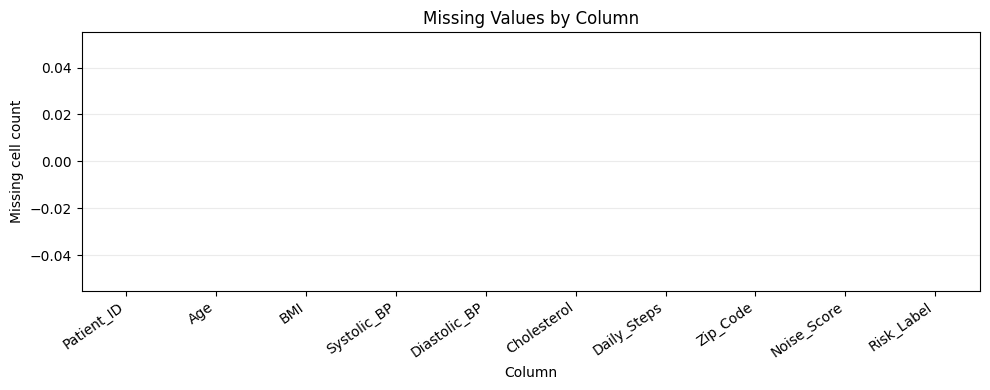

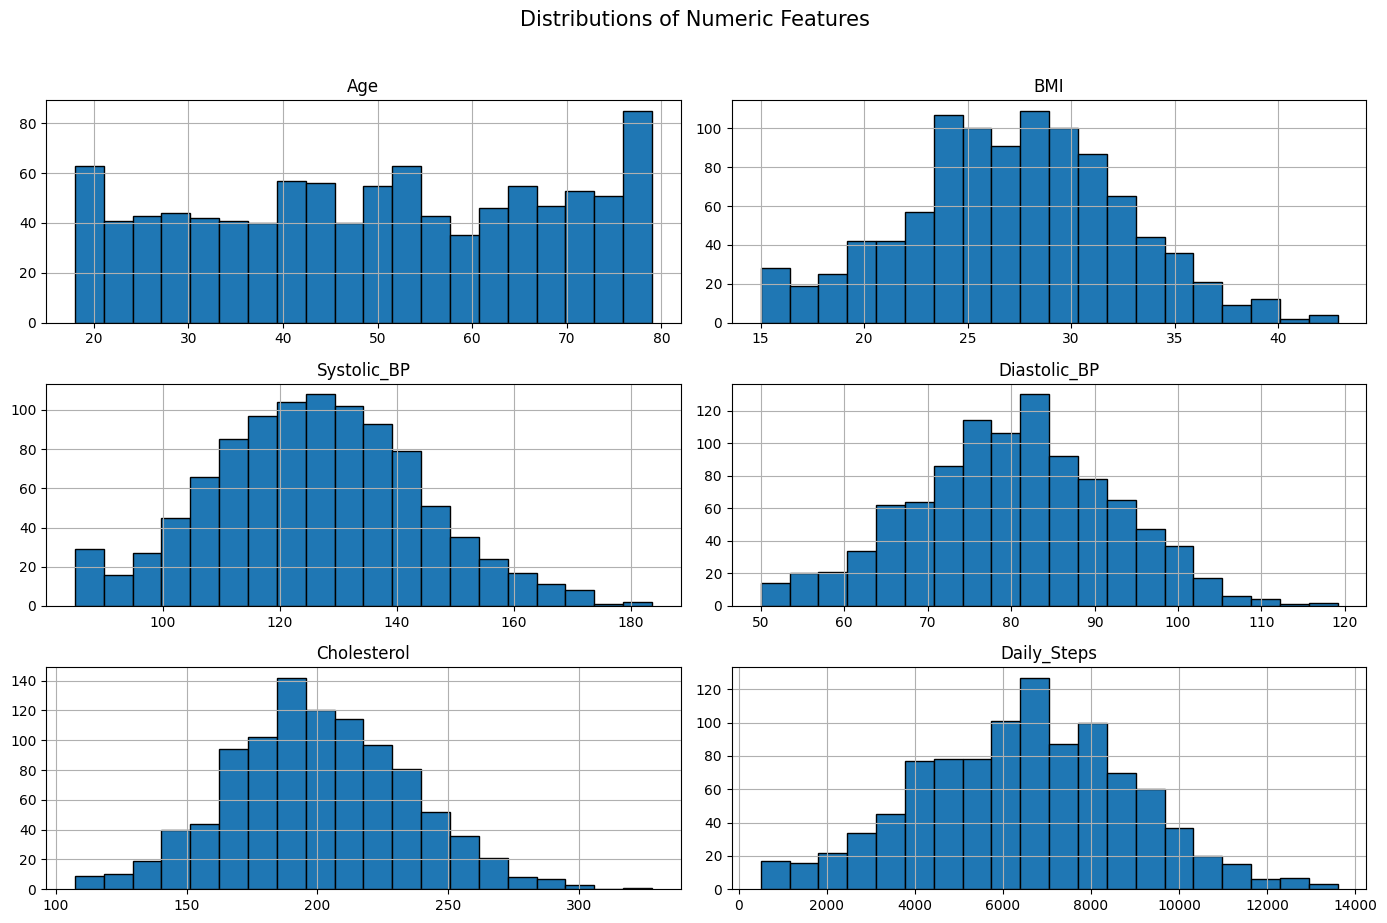

In [ ]:
# 1. Missing values by column (bar chart)
missing_counts = df.isna().sum().sort_values(ascending=False)
plt.figure(figsize=(10, 4))
missing_counts.plot(kind="bar")
plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Missing cell count")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()

# 2. Numeric feature distributions (histograms)
numeric_cols = [c for c in ["Age", "BMI", "Systolic_BP", "Diastolic_BP", "Cholesterol", "Daily_Steps"] if c in df.columns]
df[numeric_cols].hist(figsize=(14, 9), bins=20, edgecolor="black")
plt.suptitle("Distributions of Numeric Features", y=1.02, fontsize=15)
plt.tight_layout(); plt.show()

### How to read these plots
- A missing-value bar at zero means that column has no missing entries at this point in the notebook.
- A histogram shows where values are concentrated and whether the distribution is skewed or spread out.
- These pictures help identify issues, but they do not by themselves prove a value is wrong.

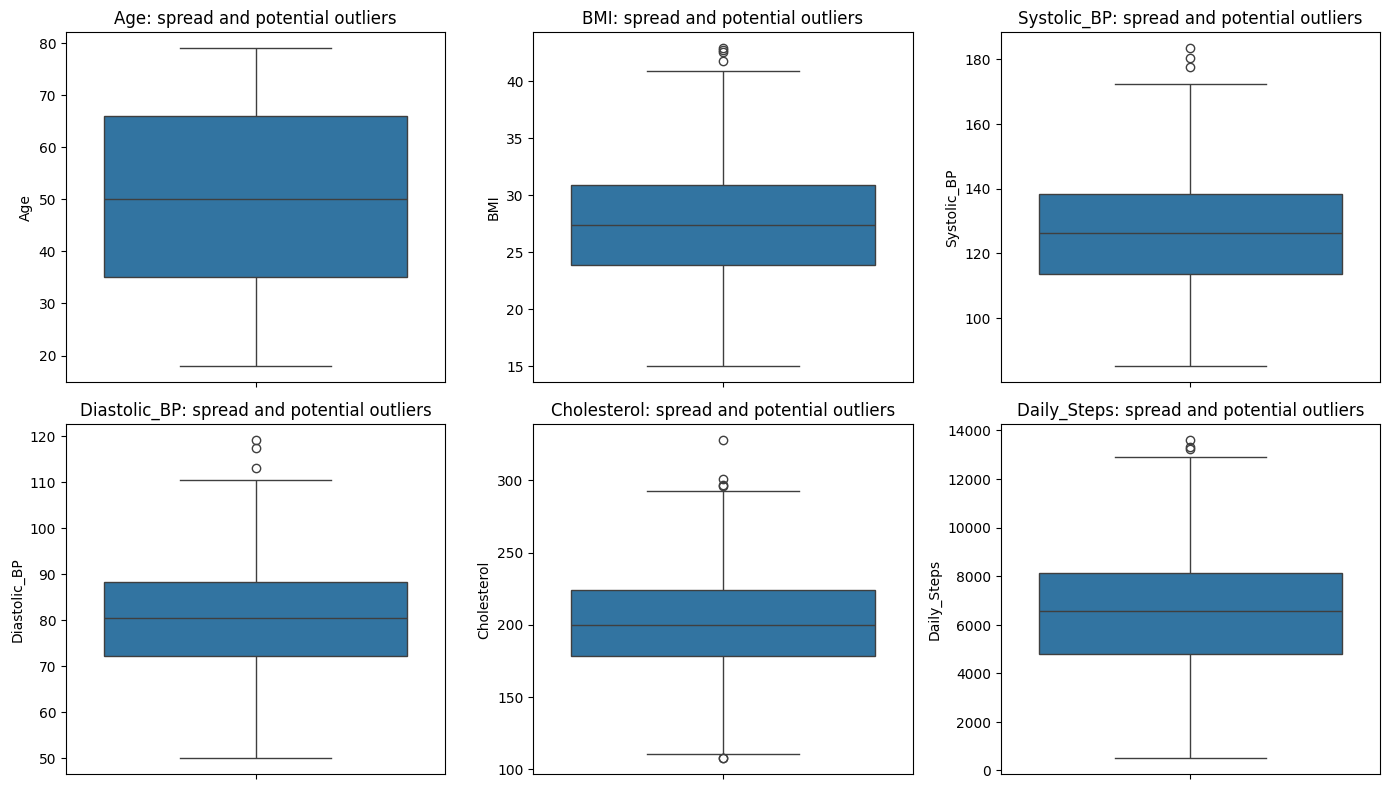

In [ ]:
# 3. Boxplots: compare spread and flag potential outliers
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f"{col}: spread and potential outliers")
    ax.set_xlabel("")
plt.tight_layout(); plt.show()

## Visualisation gallery 2: Relationships between features

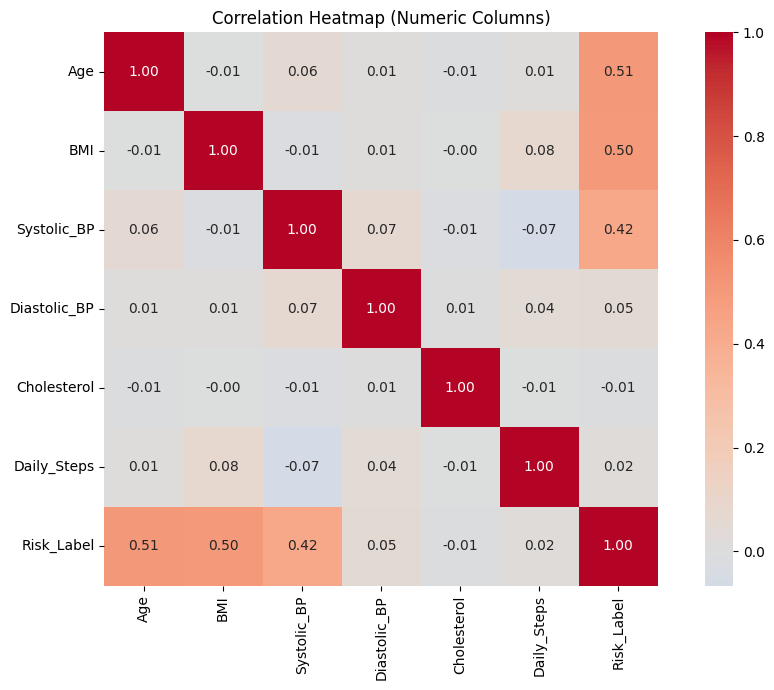

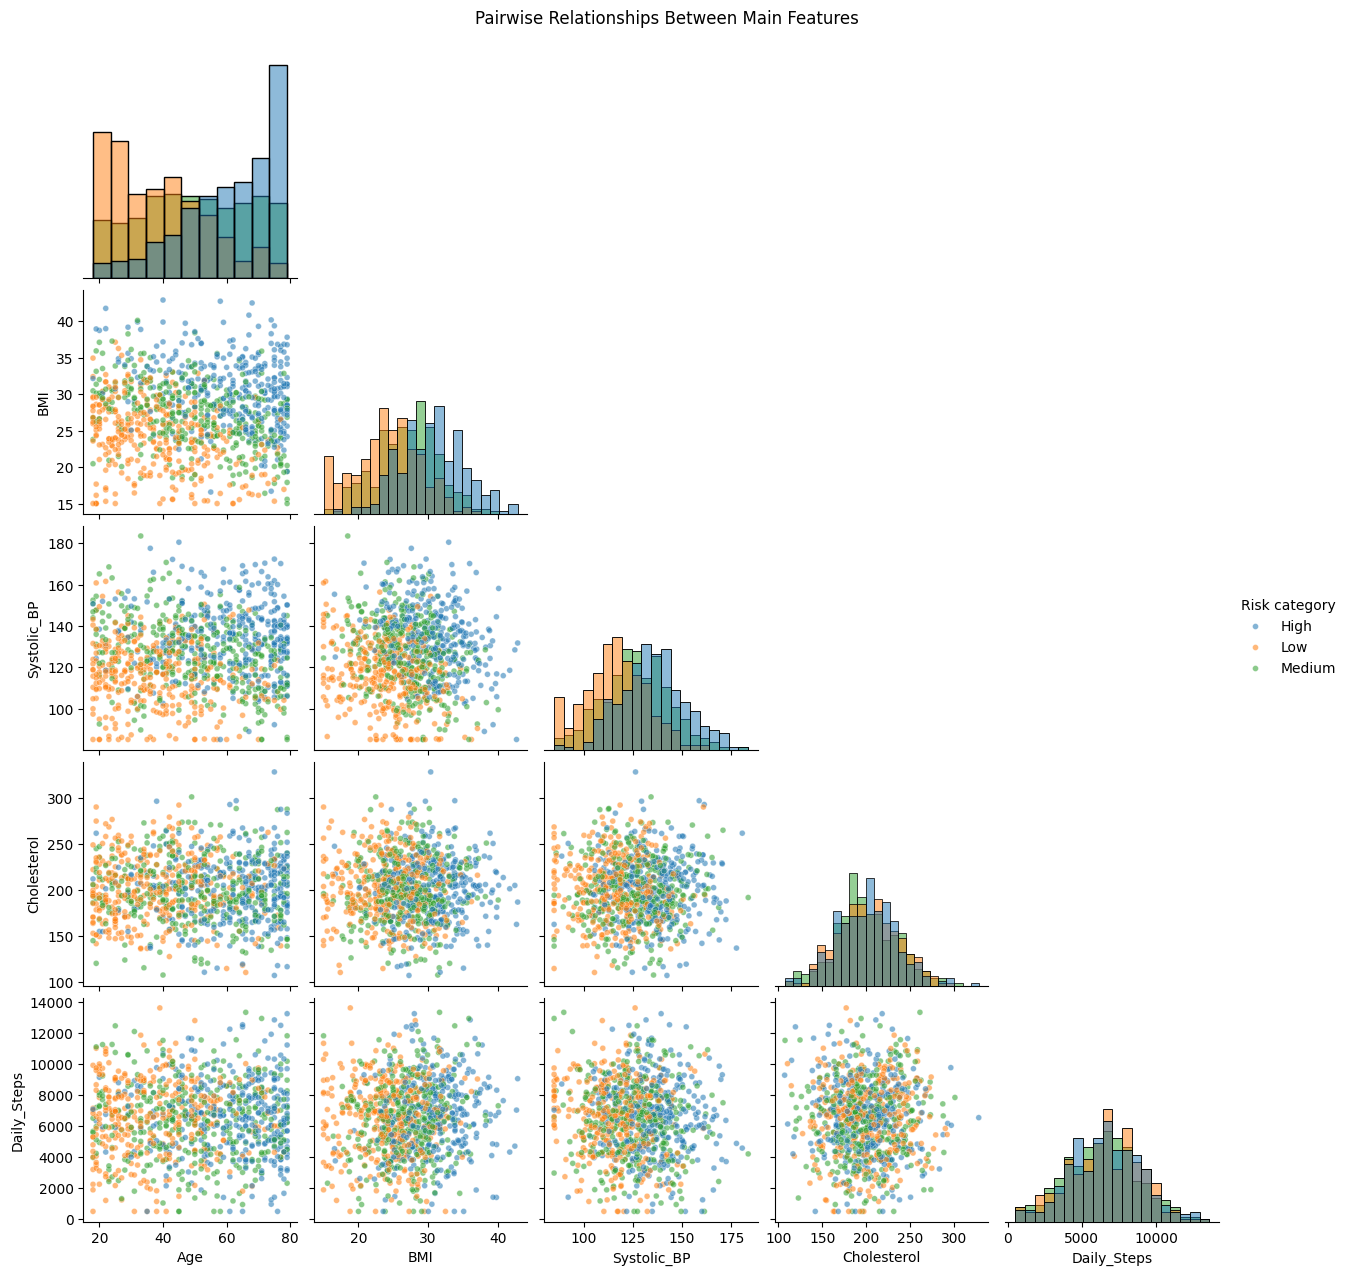

In [ ]:
label_names = {0: "Low", 1: "Medium", 2: "High"}

# 4. Correlation heatmap for numeric columns
corr_cols = numeric_cols + (["Risk_Label"] if "Risk_Label" in df.columns else [])
corr = df[corr_cols].corr(numeric_only=True)
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap (Numeric Columns)")
plt.tight_layout(); plt.show()

# 5. Pairwise scatter plots, coloured by synthetic label
pair_cols = [c for c in ["Age", "BMI", "Systolic_BP", "Cholesterol", "Daily_Steps", "Risk_Label"] if c in df.columns]
pair_df = df[pair_cols].copy()
pair_df["Risk category"] = pair_df["Risk_Label"].map(label_names)
sns.pairplot(pair_df.drop(columns="Risk_Label"), hue="Risk category", diag_kind="hist", corner=True, plot_kws={"alpha":0.55, "s":18})
plt.suptitle("Pairwise Relationships Between Main Features", y=1.02)
plt.show()

### What correlation does—and does not—tell us
Correlation summarises how two numeric columns move together in this dataset. It does not prove that one variable causes another. Pair plots let us look for overlap between classes, which matters because KNN predicts using distances between observations.

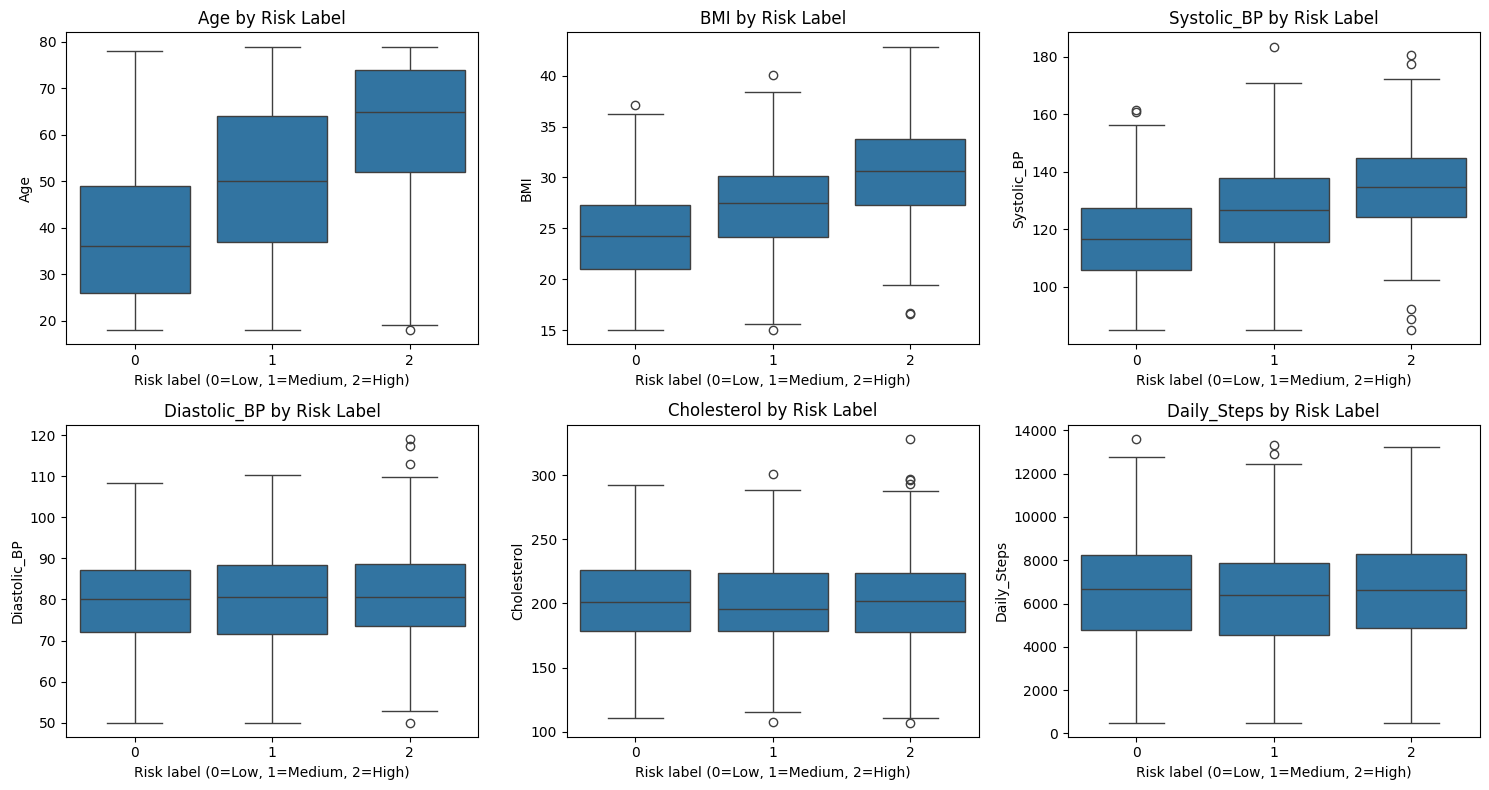

Age           BMI        Systolic_BP         Diastolic_BP  \
             mean median   mean median        mean  median         mean   
Risk_Label                                                                
0           38.58   36.0  24.13  24.26      116.35  116.57        79.26   
1           49.96   50.0  27.06  27.44      126.46  126.70        80.47   
2           61.00   65.0  30.55  30.68      134.98  134.61        80.66   

                  Cholesterol         Daily_Steps          
           median        mean  median        mean  median  
Risk_Label                                                 
0           80.03      201.74  200.74     6484.31  6650.0  
1           80.69      199.64  195.48     6322.75  6397.0  
2           80.49      200.78  201.88     6595.82  6644.0

In [ ]:
# 6. Feature distributions grouped by synthetic risk label
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(data=df, x="Risk_Label", y=col, ax=ax)
    ax.set_title(f"{col} by Risk Label")
    ax.set_xlabel("Risk label (0=Low, 1=Medium, 2=High)")
plt.tight_layout(); plt.show()

# 7. Mean and median of each numeric feature by class
class_summary = df.groupby("Risk_Label")[numeric_cols].agg(["mean", "median"]).round(2)
display(class_summary)

## Visualisation gallery 3: Before modelling

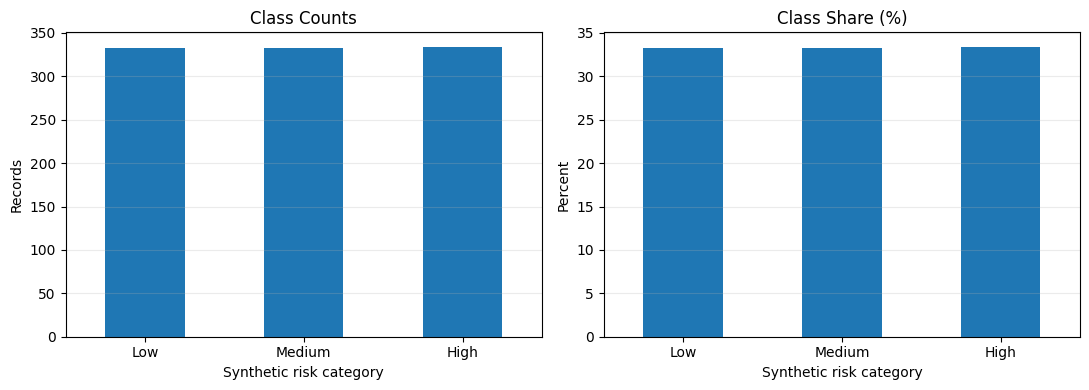

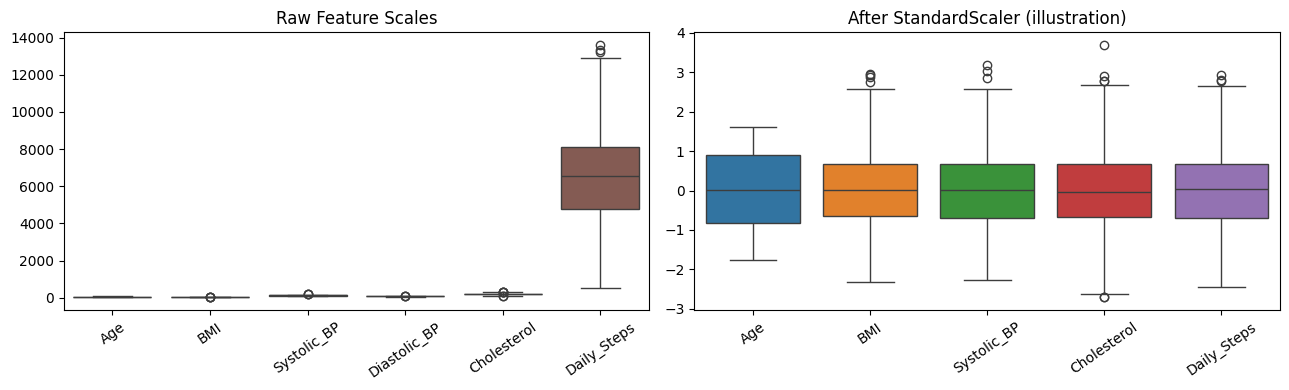

In [ ]:
# 8. Class balance: counts and percentages
class_table = df["Risk_Label"].map(label_names).value_counts().reindex(["Low", "Medium", "High"])
class_pct = (class_table / class_table.sum() * 100).round(1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
class_table.plot(kind="bar", ax=axes[0], title="Class Counts")
class_pct.plot(kind="bar", ax=axes[1], title="Class Share (%)")
for ax in axes:
    ax.set_xlabel("Synthetic risk category"); ax.tick_params(axis="x", rotation=0); ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("Records"); axes[1].set_ylabel("Percent")
plt.tight_layout(); plt.show()

# 9. Compare feature scales before standardisation
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=X if "X" in globals() else df[numeric_cols], ax=axes[0])
axes[0].set_title("Raw Feature Scales")
axes[0].tick_params(axis="x", rotation=35)
scaled_demo = StandardScaler().fit_transform(df[[c for c in ["Age", "BMI", "Systolic_BP", "Cholesterol", "Daily_Steps"] if c in df.columns]])
sns.boxplot(data=pd.DataFrame(scaled_demo, columns=[c for c in ["Age", "BMI", "Systolic_BP", "Cholesterol", "Daily_Steps"] if c in df.columns]), ax=axes[1])
axes[1].set_title("After StandardScaler (illustration)")
axes[1].tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()

**Why visualise scaling?** KNN relies on distance. A feature measured in thousands (Daily_Steps) can dominate one measured in tens (BMI) if we do not scale. The second plot illustrates the effect of standardisation. In the actual model, the scaler is fitted inside a pipeline using training folds only, helping prevent data leakage.

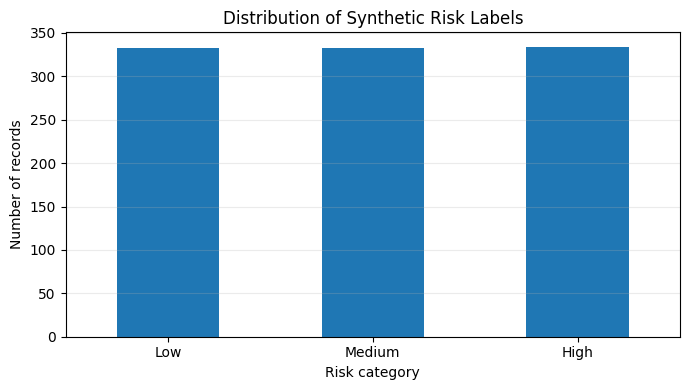

In [ ]:
# Class counts
label_names = {0: "Low", 1: "Medium", 2: "High"}
class_counts = df["Risk_Label"].map(label_names).value_counts().reindex(["Low", "Medium", "High"])

plt.figure(figsize=(7, 4))
class_counts.plot(kind="bar")
plt.title("Distribution of Synthetic Risk Labels")
plt.xlabel("Risk category")
plt.ylabel("Number of records")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

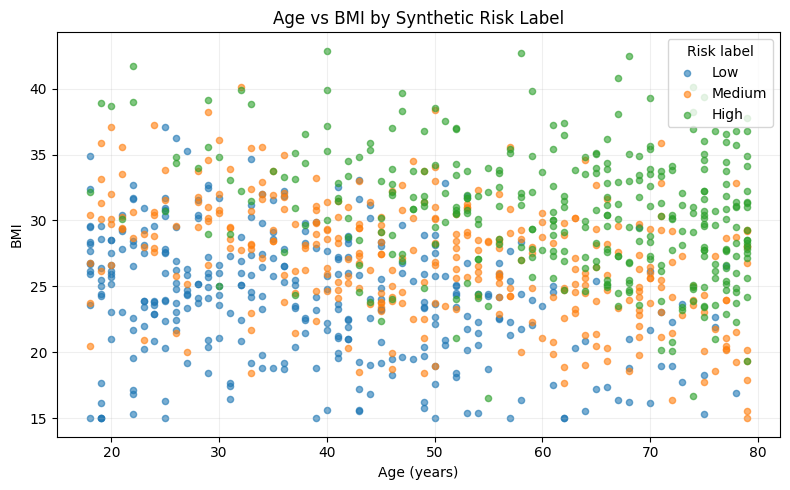

In [ ]:
# Scatter plot: age versus BMI by target class
plt.figure(figsize=(8, 5))
for label in sorted(df["Risk_Label"].unique()):
    subset = df[df["Risk_Label"] == label]
    plt.scatter(subset["Age"], subset["BMI"], label=label_names.get(label, str(label)), alpha=0.6, s=20)
plt.title("Age vs BMI by Synthetic Risk Label")
plt.xlabel("Age (years)")
plt.ylabel("BMI")
plt.legend(title="Risk label")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Why select features carefully?
- **Features (`X`)** are the information the model uses to make a prediction.
- **Target (`y`)** is the answer the model is learning to predict: `Risk_Label`.
- `Patient_ID` is an identifier, not a meaningful measurement of risk. A model could learn arbitrary patterns from IDs.
- `Zip_Code` may act as a location proxy and can introduce irrelevant or unfair patterns; it is not part of the synthetic rule that generated the label.
- `Noise_Score` was used to generate randomness in the label, but it is intentionally excluded from the selected features so the exercise uses interpretable measurements. In a real task, only use a variable if it would genuinely be available at prediction time and is appropriate.
- Never include `Risk_Label` in `X`: that would give the model the answer and cause target leakage.

## 5. Prepare features and target

In [ ]:
feature_cols = ["Age", "BMI", "Systolic_BP", "Cholesterol", "Daily_Steps"]
X = df[feature_cols]
y = df["Risk_Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Features:", feature_cols)

Training rows: 800
Test rows: 200
Features: ['Age', 'BMI', 'Systolic_BP', 'Cholesterol', 'Daily_Steps']


## Visualisation gallery 4: Train/test split

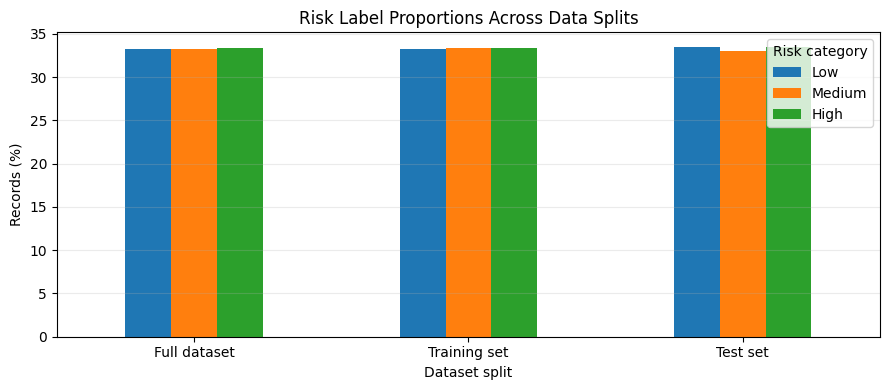

,Full dataset,Training set,Test set
Low,33.3,33.2,33.5
Medium,33.3,33.4,33.0
High,33.4,33.4,33.5


In [ ]:
# Compare label proportions in the full data, training set, and test set
prop = pd.DataFrame({
    "Full dataset": y.value_counts(normalize=True),
    "Training set": y_train.value_counts(normalize=True),
    "Test set": y_test.value_counts(normalize=True)
}).fillna(0).sort_index() * 100
prop.index = [label_names[i] for i in prop.index]
ax = prop.T.plot(kind="bar", figsize=(9, 4))
ax.set_title("Risk Label Proportions Across Data Splits")
ax.set_xlabel("Dataset split"); ax.set_ylabel("Records (%)")
ax.legend(title="Risk category"); ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()
display(prop.round(1))

A stratified split aims to preserve similar class proportions in training and test data. This plot checks whether that happened.

## Why split the data and scale features?
- **Training set:** used to fit the model.
- **Test set:** held back until the end to estimate how the chosen model performs on unseen rows.
- **Why 80/20?** It is a common simple starting point: 80% for training and 20% for testing. Other ratios can be appropriate depending on dataset size and project needs.
- **Why `stratify=y`?** It keeps the proportions of Low, Medium, and High labels roughly similar in both sets, which helps ensure each class is represented.
- **Why scale features?** KNN compares distances. Age might range around tens, cholesterol around hundreds, and daily steps around thousands. Without scaling, large-number features can dominate distance calculations simply because of their units.
- **What does `StandardScaler` do?** It transforms each feature to approximately mean 0 and standard deviation 1, using statistics learned from the training data. This puts features on comparable scales; it does not make the data normally distributed.

## 6. Tune the number of neighbours

In [ ]:
k_values = [1, 3, 5, 7, 9, 15, 21, 31]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = []
for k in k_values:
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k, weights="uniform", metric="minkowski", p=2)
    )
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    cv_results.append({"k": k, "mean_cv_accuracy": scores.mean(), "std_cv_accuracy": scores.std()})

cv_df = pd.DataFrame(cv_results)
display(cv_df)

best_k = int(cv_df.loc[cv_df["mean_cv_accuracy"].idxmax(), "k"])
print("Best k based on training-set cross-validation:", best_k)

,k,mean_cv_accuracy,std_cv_accuracy
0,1,0.64000,0.040039
1,3,0.65500,0.031967
2,5,0.67750,0.047860
3,7,0.68500,0.025495
4,9,0.69875,0.030974
5,15,0.72000,0.021433
6,21,0.72000,0.022500
7,31,0.73875,0.027783


Best k based on training-set cross-validation: 31


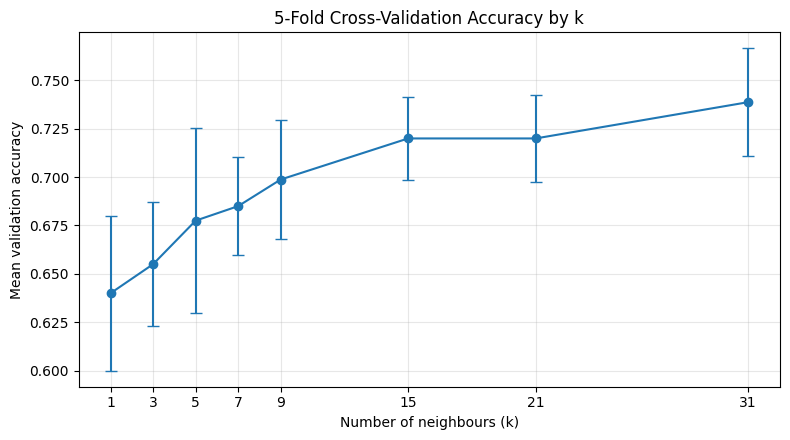

In [ ]:
plt.figure(figsize=(8, 4.5))
plt.errorbar(
    cv_df["k"], cv_df["mean_cv_accuracy"],
    yerr=cv_df["std_cv_accuracy"], marker="o", capsize=4
)
plt.title("5-Fold Cross-Validation Accuracy by k")
plt.xlabel("Number of neighbours (k)")
plt.ylabel("Mean validation accuracy")
plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## What is cross-validation, and why tune `k`?
KNN's `k` is the number of nearby training examples that vote on the class. A small `k` can be sensitive to noise; a very large `k` can smooth over local patterns. There is no universally best value.

**Five-fold cross-validation** divides the training data into five parts. Each round trains on four parts and validates on the remaining part. The process repeats until each part has served as validation data once. We average the scores and choose the candidate `k` with the best mean validation accuracy.

The scaler is inside a pipeline so it is fitted separately within each cross-validation training fold. This helps prevent validation data from influencing preprocessing. The test set is not used to choose `k`.

## 7. Train the final model and evaluate on the test set

In [ ]:
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, f1_score, precision_score, recall_score,
    balanced_accuracy_score
)

final_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=best_k, weights="uniform", metric="minkowski", p=2)
)
final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)

print(f"Test accuracy:          {accuracy_score(y_test, y_pred):.3f}")
print(f"Balanced accuracy:      {balanced_accuracy_score(y_test, y_pred):.3f}")
print(f"Macro precision:        {precision_score(y_test, y_pred, average='macro', zero_division=0):.3f}")
print(f"Macro recall:           {recall_score(y_test, y_pred, average='macro', zero_division=0):.3f}")
print(f"Macro F1-score:         {f1_score(y_test, y_pred, average='macro', zero_division=0):.3f}")
print(f"Weighted F1-score:      {f1_score(y_test, y_pred, average='weighted', zero_division=0):.3f}")

print("\\nClassification report (per-class precision, recall, F1, support):")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1, 2],
    target_names=["Low", "Medium", "High"],
    zero_division=0
))

Test accuracy:          0.710
Balanced accuracy:      0.710
Macro precision:        0.726
Macro recall:           0.710
Macro F1-score:         0.715
Weighted F1-score:      0.715
\nClassification report (per-class precision, recall, F1, support):
              precision    recall  f1-score   support

         Low       0.81      0.76      0.78        67
      Medium       0.56      0.67      0.61        66
        High       0.81      0.70      0.75        67

    accuracy                           0.71       200
   macro avg       0.73      0.71      0.71       200
weighted avg       0.73      0.71      0.72       200



## Visualisation gallery 7: Accuracy, precision, recall, F1-score and ROC-AUC

All five measures can be used with KNN classification. Accuracy, precision, recall and F1-score are based on predicted class labels; ROC-AUC uses class probability scores. Since this dataset has three classes (Low, Medium and High), ROC-AUC is calculated with a one-vs-rest strategy. These are educational metrics for synthetic labels, not evidence of medical usefulness.

,Metric,Score
0,Accuracy,0.710
1,Balanced accuracy,0.710
2,Macro precision,0.726
3,Macro recall,0.710
4,Macro F1,0.715
5,Weighted F1,0.715
6,ROC-AUC (OvR macro),0.863


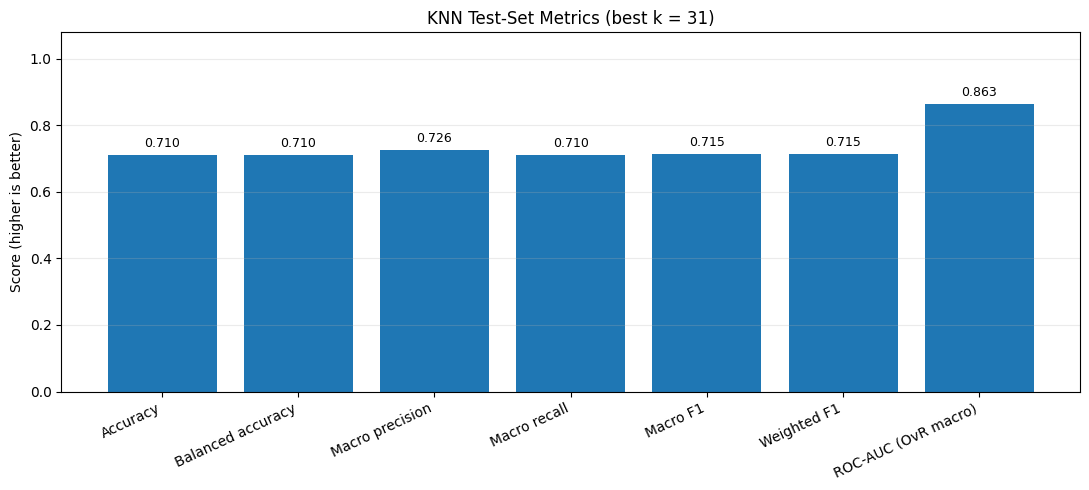

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, roc_auc_score, roc_curve, auc
)
from sklearn.preprocessing import label_binarize

# Class labels and probability estimates in the model's class order
class_order = final_model.named_steps["kneighborsclassifier"].classes_
y_prob = final_model.predict_proba(X_test)

metric_scores = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
    "Macro precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "Macro recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "Macro F1": f1_score(y_test, y_pred, average="macro", zero_division=0),
    "Weighted F1": f1_score(y_test, y_pred, average="weighted", zero_division=0),
    "ROC-AUC (OvR macro)": roc_auc_score(
        y_test, y_prob, labels=class_order, multi_class="ovr", average="macro"
    )
}
metric_summary = pd.DataFrame({"Metric": metric_scores.keys(), "Score": metric_scores.values()})
display(metric_summary.round(3))

plt.figure(figsize=(11, 5))
bars = plt.bar(metric_summary["Metric"], metric_summary["Score"])
plt.title(f"KNN Test-Set Metrics (best k = {best_k})")
plt.ylabel("Score (higher is better)")
plt.ylim(0, 1.08)
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.25)
for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, h + 0.015, f"{h:.3f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

### Compare macro and weighted averages

**Macro** gives Low, Medium and High equal importance. **Weighted** gives more influence to classes with more examples. A difference between them can signal that class sizes or class-specific performance affect the overall score. For this generated dataset the classes are designed to be roughly balanced, but the comparison is still useful to learn.

,Metric,Macro average,Weighted average
0,Precision,0.726,0.726
1,Recall,0.710,0.710
2,F1-score,0.715,0.715


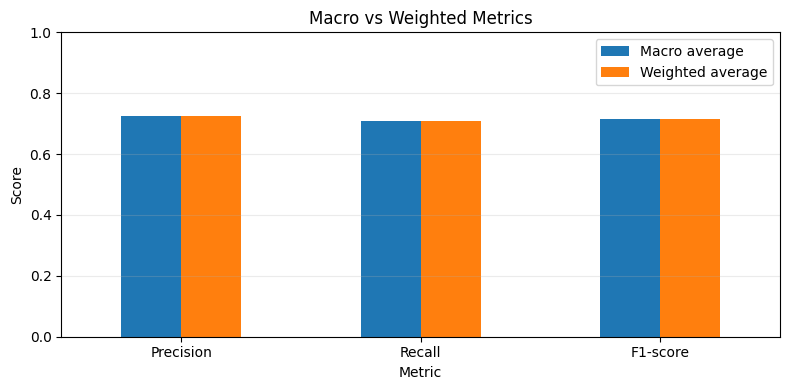

In [ ]:
average_comparison = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1-score"],
    "Macro average": [
        precision_score(y_test, y_pred, average="macro", zero_division=0),
        recall_score(y_test, y_pred, average="macro", zero_division=0),
        f1_score(y_test, y_pred, average="macro", zero_division=0)
    ],
    "Weighted average": [
        precision_score(y_test, y_pred, average="weighted", zero_division=0),
        recall_score(y_test, y_pred, average="weighted", zero_division=0),
        f1_score(y_test, y_pred, average="weighted", zero_division=0)
    ]
})
display(average_comparison.round(3))
average_comparison.plot(x="Metric", y=["Macro average", "Weighted average"], kind="bar", figsize=(8, 4), ylim=(0, 1))
plt.title("Macro vs Weighted Metrics")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Multiclass ROC curves

Each curve treats one risk class as the positive class and the other two as the negative class. The diagonal line represents chance-level ranking. AUC summarizes the curve; it is not the same as accuracy. Curves and AUC values here describe only this synthetic test set.

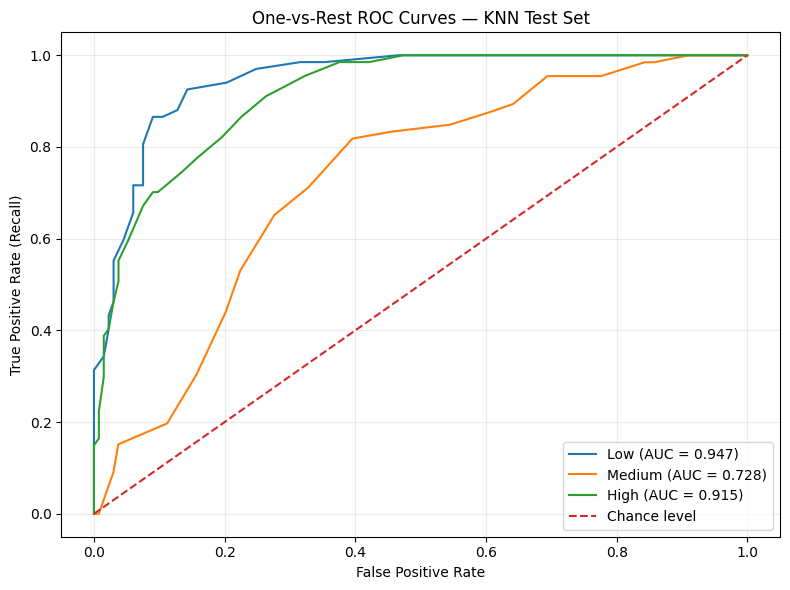

,Class,One-vs-rest AUC
0,Low,0.947
1,Medium,0.728
2,High,0.915


In [ ]:
# One-vs-rest ROC curves for each class
y_test_binary = label_binarize(y_test, classes=class_order)
plt.figure(figsize=(8, 6))
class_auc = {}
for i, class_label in enumerate(class_order):
    fpr, tpr, _ = roc_curve(y_test_binary[:, i], y_prob[:, i])
    class_auc[class_label] = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{label_names.get(class_label, class_label)} (AUC = {class_auc[class_label]:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Chance level")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("One-vs-Rest ROC Curves — KNN Test Set")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

class_auc_df = pd.DataFrame({
    "Class": [label_names.get(c, str(c)) for c in class_auc],
    "One-vs-rest AUC": list(class_auc.values())
})
display(class_auc_df.round(3))

## Visualisation gallery 8: Compare values of k using cross-validation

This comparison uses only the training split and stratified cross-validation, not the held-out test set. That helps avoid choosing `k` based on test results. We compare accuracy, macro F1 and one-vs-rest ROC-AUC. The highest score may differ by metric, so the final choice should reflect the evaluation goal rather than selecting a parameter after repeatedly checking the test set.

,k,CV accuracy,CV macro F1,CV ROC-AUC (OvR)
0,1,0.640,0.639,0.730
1,3,0.655,0.653,0.814
2,5,0.678,0.679,0.833
3,7,0.685,0.686,0.848
4,9,0.699,0.700,0.857
5,15,0.720,0.721,0.866
6,21,0.720,0.722,0.872
7,31,0.739,0.742,0.877


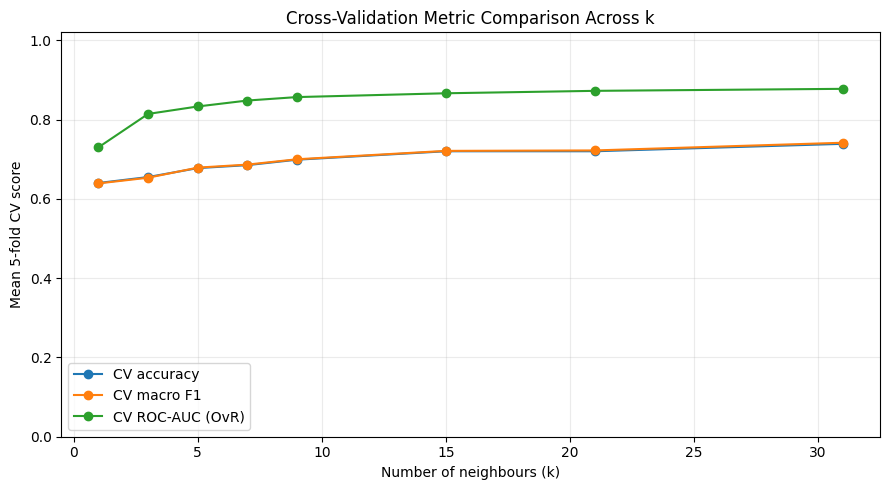

Best k by CV accuracy: 31
Best k by CV macro F1: 31
Best k by CV ROC-AUC: 31


In [ ]:
k_metric_rows = []
for k in k_values:
    candidate = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k, weights="uniform", metric="minkowski", p=2)
    )
    acc_scores = cross_val_score(candidate, X_train, y_train, cv=cv, scoring="accuracy")
    f1_scores = cross_val_score(candidate, X_train, y_train, cv=cv, scoring="f1_macro")
    auc_scores = cross_val_score(candidate, X_train, y_train, cv=cv, scoring="roc_auc_ovr")
    k_metric_rows.append({
        "k": k,
        "CV accuracy": acc_scores.mean(),
        "CV macro F1": f1_scores.mean(),
        "CV ROC-AUC (OvR)": auc_scores.mean()
    })
k_metric_df = pd.DataFrame(k_metric_rows)
display(k_metric_df.round(3))

ax = k_metric_df.plot(x="k", y=["CV accuracy", "CV macro F1", "CV ROC-AUC (OvR)"], marker="o", figsize=(9, 5))
ax.set_title("Cross-Validation Metric Comparison Across k")
ax.set_xlabel("Number of neighbours (k)")
ax.set_ylabel("Mean 5-fold CV score")
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("Best k by CV accuracy:", int(k_metric_df.loc[k_metric_df["CV accuracy"].idxmax(), "k"]))
print("Best k by CV macro F1:", int(k_metric_df.loc[k_metric_df["CV macro F1"].idxmax(), "k"]))
print("Best k by CV ROC-AUC:", int(k_metric_df.loc[k_metric_df["CV ROC-AUC (OvR)"].idxmax(), "k"]))

### How to explain the comparison
- **Accuracy** counts all correct predictions, so it is easy to interpret but can hide poor performance on an individual class.
- **Precision** reflects how trustworthy predictions for a class are.
- **Recall** reflects how many actual examples of a class are found.
- **F1-score** balances precision and recall.
- **ROC-AUC** assesses how well probability scores rank members of a class above non-members across thresholds.
- **Macro vs weighted** shows whether giving every class equal importance changes the summary.
- **k comparison** shows whether the preferred number of neighbours changes depending on the metric.

Do not describe a high score on this synthetic dataset as clinical validation. The labels were generated artificially for practice.

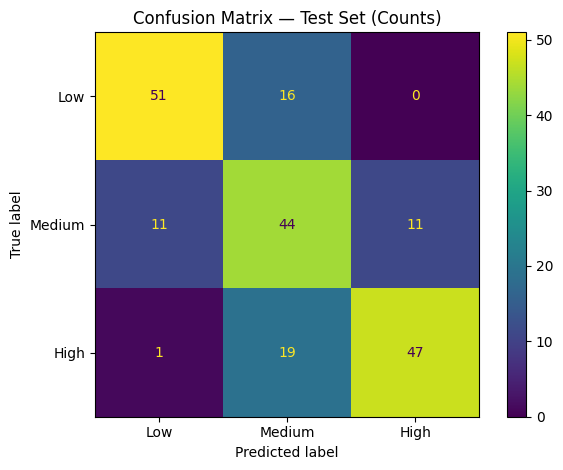

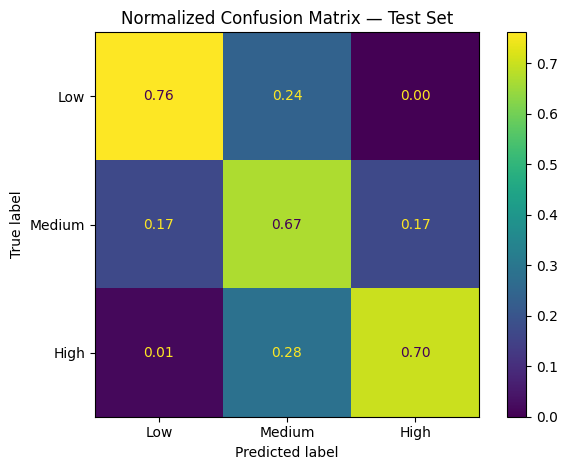

In [ ]:
# Raw confusion matrix: counts of actual versus predicted classes
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Low", "Medium", "High"])
disp.plot(values_format="d")
plt.title("Confusion Matrix — Test Set (Counts)")
plt.tight_layout()
plt.show()

# Normalized confusion matrix: each row shows proportions for an actual class
disp_norm = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=[0, 1, 2],
    display_labels=["Low", "Medium", "High"],
    normalize="true",
    values_format=".2f"
)
plt.title("Normalized Confusion Matrix — Test Set")
plt.tight_layout()
plt.show()

## Visualisation gallery 5: Model performance in more detail

,Precision,Recall,F1-score,Support
Low,0.810,0.761,0.785,67
Medium,0.557,0.667,0.607,66
High,0.810,0.701,0.752,67


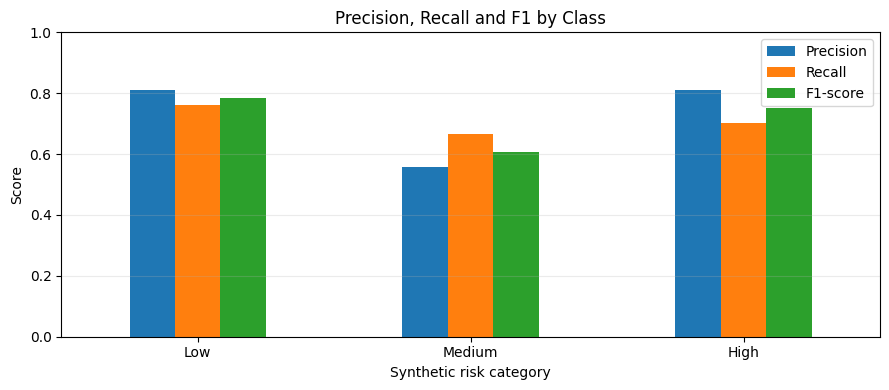

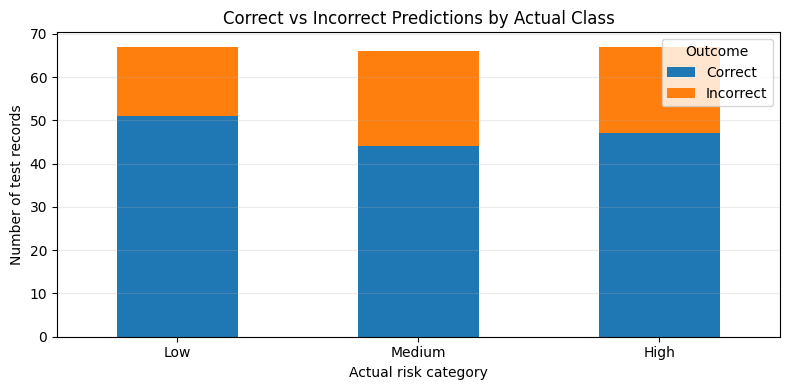

In [ ]:
# 10. Per-class precision, recall, and F1 score
from sklearn.metrics import precision_recall_fscore_support
prec, rec, f1, support = precision_recall_fscore_support(y_test, y_pred, labels=[0,1,2], zero_division=0)
metric_by_class = pd.DataFrame({"Precision":prec, "Recall":rec, "F1-score":f1, "Support":support}, index=["Low", "Medium", "High"])
display(metric_by_class.round(3))
metric_by_class[["Precision", "Recall", "F1-score"]].plot(kind="bar", figsize=(9, 4), ylim=(0, 1))
plt.title("Precision, Recall and F1 by Class")
plt.xlabel("Synthetic risk category"); plt.ylabel("Score")
plt.xticks(rotation=0); plt.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()

# 11. Prediction outcome counts
outcomes = pd.DataFrame({"Actual": y_test.map(label_names).values, "Predicted": pd.Series(y_pred, index=y_test.index).map(label_names).values})
outcomes["Outcome"] = np.where(outcomes["Actual"] == outcomes["Predicted"], "Correct", "Incorrect")
outcome_counts = outcomes.groupby(["Actual", "Outcome"]).size().unstack(fill_value=0).reindex(["Low", "Medium", "High"])
outcome_counts.plot(kind="bar", stacked=True, figsize=(8, 4))
plt.title("Correct vs Incorrect Predictions by Actual Class")
plt.xlabel("Actual risk category"); plt.ylabel("Number of test records")
plt.xticks(rotation=0); plt.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()

### Reading the performance plots
- **Precision:** of predictions assigned to a class, how many were correct?
- **Recall:** of the actual examples in a class, how many did the model find?
- **F1-score:** balances precision and recall.
- **Support:** number of actual test examples in that class.
The correct/incorrect plot helps reveal whether errors are concentrated in one class. Since the labels are synthetic, these metrics measure performance on the generated rules—not real-world health prediction.

## Understanding the evaluation metrics
- **Confusion matrix:** rows represent the actual class and columns represent the predicted class (as labelled by scikit-learn). The diagonal cells are correct predictions; off-diagonal cells show which classes were confused.
- **Accuracy:** correct predictions divided by all predictions. Easy to explain, but it can hide poor performance on a less common class.
- **Precision for a class:** among records predicted as that class, the fraction that truly belongs to it. Low precision means more false positives for that class.
- **Recall for a class:** among records that truly belong to that class, the fraction found by the model. Low recall means more false negatives for that class.
- **F1-score:** the harmonic mean of precision and recall. It is high only when both precision and recall are reasonably high.
- **Macro average:** calculate a metric separately for each class and then average classes equally. Useful when you want every class to count equally.
- **Weighted average:** averages class scores weighted by each class's number of true examples.
- **Balanced accuracy:** averages recall across classes, giving each class equal weight. It can be more informative than ordinary accuracy when class counts differ.
- **Support:** the number of true test examples in each class.

For the confusion matrix, a row-normalized value such as 0.80 means 80% of examples from that actual class were predicted into the corresponding column. Metrics here are for a synthetic educational task, not clinical performance.

## 8. Compare feature sets

,Feature set,Best k,Mean CV accuracy
0,Without Diastolic_BP,31,0.73875
1,With Diastolic_BP,21,0.72250


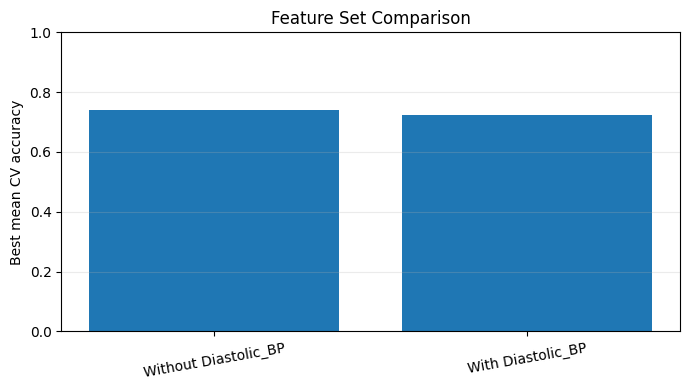

In [ ]:
feature_sets = {
    "Without Diastolic_BP": ["Age", "BMI", "Systolic_BP", "Cholesterol", "Daily_Steps"],
    "With Diastolic_BP": ["Age", "BMI", "Systolic_BP", "Diastolic_BP", "Cholesterol", "Daily_Steps"]
}

comparison_rows = []
for set_name, cols in feature_sets.items():
    X_variant = df[cols]
    Xv_train, Xv_test, yv_train, yv_test = train_test_split(
        X_variant, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
    )
    candidate_scores = []
    for k in k_values:
        candidate = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
        scores = cross_val_score(candidate, Xv_train, yv_train, cv=cv, scoring="accuracy")
        candidate_scores.append((k, scores.mean()))
    best_variant_k, best_variant_score = max(candidate_scores, key=lambda item: item[1])
    comparison_rows.append({
        "Feature set": set_name,
        "Best k": best_variant_k,
        "Mean CV accuracy": best_variant_score
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

plt.figure(figsize=(7, 4))
plt.bar(comparison_df["Feature set"], comparison_df["Mean CV accuracy"])
plt.title("Feature Set Comparison")
plt.ylabel("Best mean CV accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=10)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## Visualisation gallery 6: Feature-set comparison

In [ ]:
# Compare feature-set performance visually (uses results from the comparison cell above)
comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)
score_col = next((c for c in comparison_df.columns if "accuracy" in c.lower() and "cv" not in c.lower()), None)
if score_col is None:
    score_col = next((c for c in comparison_df.columns if "f1" in c.lower()), None)
if score_col is not None:
    comparison_df.plot(x=comparison_df.columns[0], y=score_col, kind="bar", legend=False, figsize=(8,4))
    plt.title(f"Feature-Set Comparison: {score_col}")
    plt.xlabel("Feature set"); plt.ylabel(score_col)
    plt.xticks(rotation=0); plt.grid(axis="y", alpha=0.25)
    plt.tight_layout(); plt.show()
else:
    print("Review the comparison table above; column names may differ from this plotting template.")

,Feature set,Best k,Mean CV accuracy
0,Without Diastolic_BP,31,0.73875
1,With Diastolic_BP,21,0.72250


Review the comparison table above; column names may differ from this plotting template.


## 9. KNN parameters used

- `n_neighbors`: the number of neighbours (`k`) considered for a prediction; selected here using cross-validation.
- `weights="uniform"`: each neighbour has equal voting weight.
- `metric="minkowski", p=2`: Euclidean distance.
- `StandardScaler()`: standardizes numeric features before distance calculations.
- `test_size=0.20`: keeps 20% of rows for final evaluation.
- `StratifiedKFold(n_splits=5)`: performs 5-fold cross-validation while preserving class proportions as much as possible.

## 10. Discussion questions
1. Why should features be scaled before using KNN?
2. What can happen when `k` is too small? What about when `k` is too large?
3. Why should identifiers and random-noise columns be excluded?
4. What does the confusion matrix tell us that accuracy alone does not?
5. Why must the test set be kept separate from parameter tuning?
6. Why should these synthetic labels not be interpreted as real health-risk predictions?

## Conclusion
KNN classifies a record based on nearby examples. In this practical, you explored a synthetic dataset, scaled its features, selected `k` using cross-validation, and evaluated the chosen model on a held-out test set. All results are for learning purposes only.


## Visualisation checklist

This notebook visualises data quality, distributions, potential outliers, correlations, pairwise feature relationships, feature distributions by synthetic class, class balance, scaling, train/test proportions, cross-validation performance, confusion matrices, per-class precision/recall/F1, correct versus incorrect predictions, feature-set comparisons, overall metric comparisons, macro-versus-weighted metrics, multiclass ROC curves, and cross-validation comparisons of accuracy, macro F1 and ROC-AUC across values of `k`.

**Reminder:** This is synthetic educational data, not a clinical risk assessment tool.